# Surface albedo

A first parameter sweep: wavelength-integrated irradiance (400–700 nm) for 20 surface albedo values at one time and place. It follows the basic workflow: build a config, create an input dataset, run, plot.

## Setup and run

The albedo values sit on their own dimension (`albedo`). pyRadtran loops over it like over any other dimension ({doc}`/guide/concepts`), and `Var('surface_albedo')` passes each value to the uvspec option `albedo`. An `altitude` coordinate turns each run into a vertical profile (`zout 0 1 … 99`). Broadband solar output is in mW m⁻²; the plots divide by 1000 for W m⁻² ({ref}`units <units>`).

In [1]:
import pyradtran  # Registers the .pyradtran xarray accessor
from pyradtran import Var
from pyradtran import load_config
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd
from pathlib import Path
import logging

# Show warnings only (set to DEBUG to see every uvspec call)
logging.getLogger('pyradtran').setLevel(logging.WARNING)

# ── Simulation parameters ─────────────────────────────────────────────────────
# Start from merged defaults + master config (~/.pyradtran/config.yaml)
cfg = load_config()

# Spectral range and solver
cfg.simulation_defaults.wavelength_nm        = [400, 700]   # broadband visible
cfg.simulation_defaults.rte_solver           = "disort"
cfg.simulation_defaults.mol_abs_param        = "lowtran per_nm"
cfg.simulation_defaults.source               = "solar"
cfg.simulation_defaults.integrate_wavelength = True

# Output
cfg.simulation_defaults.output_altitudes_km  = [0.0]
cfg.simulation_defaults.output_columns       = ["sza", "edir", "eglo", "edn", "eup", "enet"]

# Execution
cfg.execution.max_workers        = 1
cfg.execution.cleanup_temp_files = False

# Save so the run is reproducible
config_path = Path("config/albedo.yaml")
cfg.to_yaml(config_path)
print(f"Config saved to {config_path}")

# ── Input dataset ─────────────────────────────────────────────────────────────
# One time step at Leipzig, Germany; output levels 0-99 km every 1 km;
# 20 albedo values as a sweep dimension
N_albedo = 20
albedo_values = np.linspace(0.1, 0.9, N_albedo)

ds = xr.Dataset(
    coords={
        'time': [pd.to_datetime('2025-04-04T08:00:00')],
        'latitude': ('time', [51.34]),
        'longitude': ('time', [12.37]),
        'altitude': ('altitude', np.arange(0, 100, 1)),
        'albedo': ('albedo', albedo_values),
    },
)
ds['surface_albedo'] = ds.albedo   # variable for Var() to reference

# ── Run ───────────────────────────────────────────────────────────────────────
ds_sim = ds.pyradtran.run(
    config_path=config_path,
    params={'albedo': Var('surface_albedo')},  # one uvspec `albedo` line per point
    show_progress=False,
)

print("Simulation complete!")
print(f"Variables: {list(ds_sim.data_vars.keys())}")
print(f"Dimensions: {dict(ds_sim.sizes)}")

Config saved to config/albedo.yaml


Simulation complete!
Variables: ['sza', 'edir', 'eglo', 'edn', 'eup', 'enet', 'status']
Dimensions: {'time': 1, 'albedo': 20, 'altitude': 100}


In [2]:
ds_sim

<xarray.Dataset> Size: 97kB
Dimensions:   (time: 1, albedo: 20, altitude: 100)
Coordinates:
  * time      (time) datetime64[ns] 8B 2025-04-04T08:00:00
  * albedo    (albedo) float64 160B 0.1 0.1421 0.1842 ... 0.8158 0.8579 0.9
  * altitude  (altitude) float64 800B 0.0 1.0 2.0 3.0 ... 96.0 97.0 98.0 99.0
Data variables:
    sza       (time, albedo, altitude) float64 16kB 60.51 60.51 ... 60.51 60.51
    edir      (time, albedo, altitude) float64 16kB 1.955e+05 ... 2.631e+05
    eglo      (time, albedo, altitude) float64 16kB 2.259e+05 ... 2.631e+05
    edn       (time, albedo, altitude) float64 16kB 3.045e+04 ... 0.02634
    eup       (time, albedo, altitude) float64 16kB 2.259e+04 ... 2.202e+05
    enet      (time, albedo, altitude) float64 16kB 2.033e+05 ... 4.285e+04
    status    (time, albedo) int64 160B 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
Attributes:
    generated_by:              pyradtran
    generation_date:           2026-11-14T14:10:57.388647
    pyradtran_version:         0.2.0
    history:                   2026-11-14T14:10:57: pyradtran 0.2.0 ds.pyradt...
    pyradtran_params:          {"albedo": "Var(name='surface_albedo')"}
    pyradtran_libradtran_bin:  /opt/libRadtran-2.0.6/bin/uvspec
    pyradtran_config:          paths: {libradtran_bin: /opt/libRadtran-2.0.6/...
    pyradtran_input_example:   rte_solver disort                             ...

## Altitude profiles

Upward irradiance against altitude, one line per albedo value:

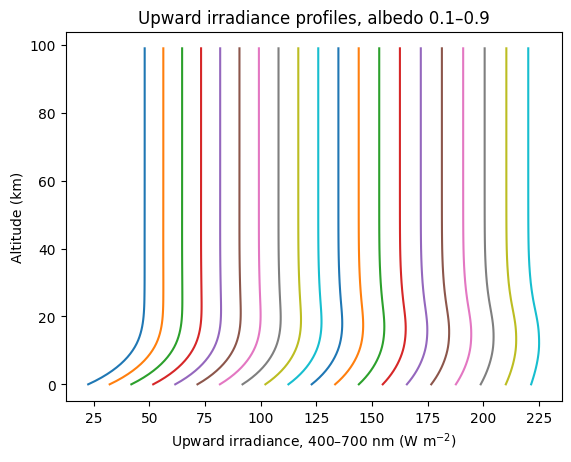

In [3]:
(ds_sim.eup.squeeze() / 1e3).plot(hue='albedo', y='altitude', add_legend=False)
plt.xlabel('Upward irradiance, 400–700 nm (W m$^{-2}$)')
plt.ylabel('Altitude (km)')
plt.title('Upward irradiance profiles, albedo 0.1–0.9')
plt.show()

## Albedo dependence

Upward irradiance at the surface against albedo. With `disort` the surface is
Lambertian, so `eup / eglo` reproduces the input albedo; `eglo` itself grows
slightly with albedo through multiple reflection between surface and sky.

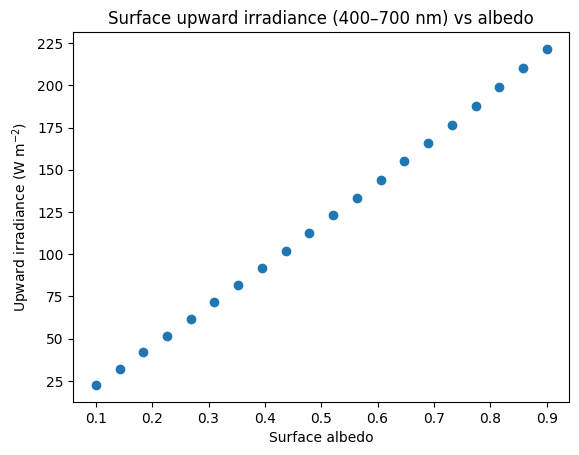

max |eup / eglo - albedo| = 2.4e-07


In [4]:
sfc = ds_sim.sel(altitude=0).squeeze()
plt.scatter(sfc.albedo, sfc.eup / 1e3)
plt.title('Surface upward irradiance (400–700 nm) vs albedo')
plt.xlabel('Surface albedo')
plt.ylabel('Upward irradiance (W m$^{-2}$)')
plt.show()

# disort returns a Lambertian surface: eup = albedo * eglo
print(f"max |eup / eglo - albedo| = {float(abs(sfc.eup / sfc.eglo - sfc.albedo).max()):.1e}")